# Customer Churn Analysis: Customer Segmentation (K-Means Clustering)
**Team 8 | Role: Data Analyst (Clustering) | Jyoti Saini**

This notebook groups the telecom company's customers into segments using K-Means clustering. It continues from the Data Engineer's preprocessing (Part 1) and uses its output, `data/Updated_Dataset.csv`, together with the original client file, `data/Dataset_ATS_v2.csv`, which is used only to describe each segment in real units (months and dollars).

**Steps**
1. Load the data and check that it is ready for clustering
2. Finish the processing that clustering needs (encoding and feature types)
3. Select and scale the clustering features
4. Find the best number of clusters (elbow method and silhouette score)
5. Train the final K-Means model
6. Visualise the clusters (PCA and tenure vs monthly charges)
7. Profile and name each segment, and compare churn across segments
8. Save the results for the Data Analyst (Predictive) and Business Analyst

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

# Fixed colour for each cluster (colour-blind checked palette)
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
RANDOM_STATE = 42

## 1. Load the data and check readiness

In [2]:
processed = pd.read_csv("../data/Updated_Dataset.csv")   # output of the Data Engineer's notebook
raw = pd.read_csv("../data/Dataset_ATS_v2.csv")          # original client file, used for profiling only

print("Processed dataset:", processed.shape)
print("Raw dataset:      ", raw.shape)
processed.head()

Processed dataset: (7043, 11)
Raw dataset:       (7043, 10)


,gender,SeniorCitizen,Dependents,tenure,MonthlyCharges,Churn,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,Female,-0.439916,No,-1.277445,-1.321350,Yes,False,False,False,False,False
1,Male,-0.439916,No,0.351370,-1.321350,No,True,False,False,True,False
2,Female,-0.439916,Yes,0.799294,-1.520755,No,True,False,False,False,False
3,Female,-0.439916,No,-1.277445,0.373593,Yes,True,False,False,True,False
4,Male,-0.439916,No,1.410099,-0.457261,No,True,False,True,False,False


In [3]:
print("Data types in the processed dataset:")
print(processed.dtypes)

Data types in the processed dataset:
gender                             str
SeniorCitizen                  float64
Dependents                         str
tenure                         float64
MonthlyCharges                 float64
Churn                              str
PhoneService_Yes                  bool
MultipleLines_Yes                 bool
InternetService_Fiber optic       bool
Contract_One year                 bool
Contract_Two year                 bool
dtype: object


In [4]:
print("Missing values (processed):", int(processed.isnull().sum().sum()))
print("Missing values (raw):      ", int(raw.isnull().sum().sum()))
print("Duplicate rows (raw):      ", raw.duplicated().sum())

# The processed file keeps the same row order as the raw file, so the two can be joined row by row
same_order = (processed["Churn"].values == raw["Churn"].values).all() and \
             (processed["Dependents"].values == raw["Dependents"].values).all()
print("Rows line up with the raw file:", same_order)

Missing values (processed): 0
Missing values (raw):       0
Duplicate rows (raw):       302
Rows line up with the raw file: True


In [5]:
# Check for inconsistent category labels
for col in ["gender", "Dependents", "PhoneService", "MultipleLines", "InternetService", "Contract", "Churn"]:
    print(f"{col:16s}", sorted(raw[col].unique()))

gender           ['Female', 'Male']
Dependents       ['No', 'Yes']
PhoneService     ['No', 'Yes']
MultipleLines    ['No', 'Yes']
InternetService  ['DSL', 'Fiber optic']
Contract         ['Month-to-month', 'One year', 'Two year']
Churn            ['No', 'Yes']


**Readiness findings**

- There are no missing values and the category labels are consistent.
- The raw file has **302 duplicate rows**. The dataset has no customer ID, and with only ten attributes it is quite possible for two different customers to have exactly the same profile. Removing them would change the size of the segments without any evidence that they are errors, so they are **kept**. This also keeps my data aligned with the dataset the Data Engineer prepared for the ANN model.
- Part 1 has standardised the numerical columns and one-hot encoded the service and contract columns as booleans. For K-Means, which needs every input as a number, three small adjustments are made on a separate copy (the Part 1 data is left unchanged):
  - `gender` and `Dependents` are converted from `Male/Female` and `Yes/No` to 0/1.
  - `SeniorCitizen` is used in its original 0/1 form, so that it reads as a simple yes/no flag in the cluster profiles.
  - The boolean dummy columns are converted from `True/False` to 1/0.
- The dataset has no `TotalCharges` or `PaymentMethod` columns, so these cannot be used.

## 2. Finish the processing needed for clustering

In [6]:
df = processed.copy()

df["gender"] = (df["gender"] == "Male").astype(int)            # 1 = Male, 0 = Female
df["Dependents"] = (df["Dependents"] == "Yes").astype(int)      # 1 = has dependents
df["SeniorCitizen"] = raw["SeniorCitizen"].astype(int)          # restore the 0/1 flag
df["Churn"] = (df["Churn"] == "Yes").astype(int)                # kept aside, NOT used for clustering

bool_cols = df.select_dtypes(include="bool").columns
df[bool_cols] = df[bool_cols].astype(int)

df.head()

,gender,SeniorCitizen,Dependents,tenure,MonthlyCharges,Churn,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,Contract_One year,Contract_Two year
0,0,0,0,-1.277445,-1.321350,1,0,0,0,0,0
1,1,0,0,0.351370,-1.321350,0,1,0,0,1,0
2,0,0,1,0.799294,-1.520755,0,1,0,0,0,0
3,0,0,0,-1.277445,0.373593,1,1,0,0,1,0
4,1,0,0,1.410099,-0.457261,0,1,0,1,0,0


## 3. Select and scale the clustering features

**Excluded from clustering**

- **Churn** is the outcome we want to explain. If it were included, the model would simply split customers into "left" and "stayed". Keeping it out lets the segments form on customer characteristics only, and churn is compared across them afterwards.
- **Gender** is excluded. It describes who the customer is rather than how they use the service, and the check below shows that churn is almost the same for both genders, so it would add noise without helping to separate customers.

In [7]:
print("Churn rate by gender:")
print((raw.groupby("gender")["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).round(1))

Churn rate by gender:
gender
Female    26.9
Male      26.2
Name: Churn, dtype: float64


In [8]:
features = ["tenure", "MonthlyCharges", "SeniorCitizen", "Dependents",
            "PhoneService_Yes", "MultipleLines_Yes", "InternetService_Fiber optic",
            "Contract_One year", "Contract_Two year"]

X = df[features].copy()
X.describe().round(2)

,tenure,MonthlyCharges,SeniorCitizen,Dependents,PhoneService_Yes,MultipleLines_Yes,InternetService_Fiber optic,Contract_One year,Contract_Two year
count,7043.00,7043.00,7043.00,7043.00,7043.0,7043.00,7043.00,7043.00,7043.00
mean,-0.00,-0.00,0.16,0.30,0.9,0.42,0.44,0.21,0.24
std,1.00,1.00,0.37,0.46,0.3,0.49,0.50,0.41,0.43
min,-1.32,-1.55,0.00,0.00,0.0,0.00,0.00,0.00,0.00
25%,-0.95,-0.96,0.00,0.00,1.0,0.00,0.00,0.00,0.00
50%,-0.14,0.17,0.00,0.00,1.0,0.00,0.00,0.00,0.00
75%,0.92,0.84,0.00,1.00,1.0,1.00,1.00,0.00,0.00
max,1.61,1.80,1.00,1.00,1.0,1.00,1.00,1.00,1.00


**Scaling.** `tenure` (0 to 72 months) and `MonthlyCharges` (18 to 119 dollars) are on very different scales. The Data Engineer has already standardised them (mean 0, standard deviation 1), which the summary above confirms, so they are used as they are. The remaining features are 0/1 flags, which already sit on a small, common range, so they are left unscaled. This stops any single variable from dominating the distance calculation that K-Means relies on.

In [9]:
print("tenure mean / std:        ", round(X["tenure"].mean(), 3), "/", round(X["tenure"].std(), 3))
print("MonthlyCharges mean / std:", round(X["MonthlyCharges"].mean(), 3), "/", round(X["MonthlyCharges"].std(), 3))

tenure mean / std:         -0.0 / 1.0
MonthlyCharges mean / std: -0.0 / 1.0


## 4. Find the best number of clusters

I test k = 1 to 10. The **elbow method** plots inertia (how tightly customers sit around their cluster centre) and looks for the point where adding another cluster stops giving a large improvement. The **silhouette score** (from -1 to 1) checks how well each customer fits its own cluster compared with the nearest other cluster.

In [10]:
k_values = range(1, 11)
inertia, silhouette = [], []

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, labels, sample_size=5000, random_state=RANDOM_STATE) if k > 1 else np.nan)

results = pd.DataFrame({"k": list(k_values), "inertia": np.round(inertia, 0),
                        "drop_in_inertia": np.round(-np.diff([np.nan] + inertia), 0),
                        "silhouette": np.round(silhouette, 3)})
results

,k,inertia,drop_in_inertia,silhouette
0,1,23041.0,NaN,NaN
1,2,16777.0,6264.0,0.246
2,3,13442.0,3334.0,0.232
3,4,11620.0,1823.0,0.223
4,5,10930.0,689.0,0.200
5,6,10368.0,563.0,0.178
6,7,9978.0,390.0,0.161
7,8,9504.0,474.0,0.162
8,9,9238.0,266.0,0.153
9,10,8910.0,328.0,0.163


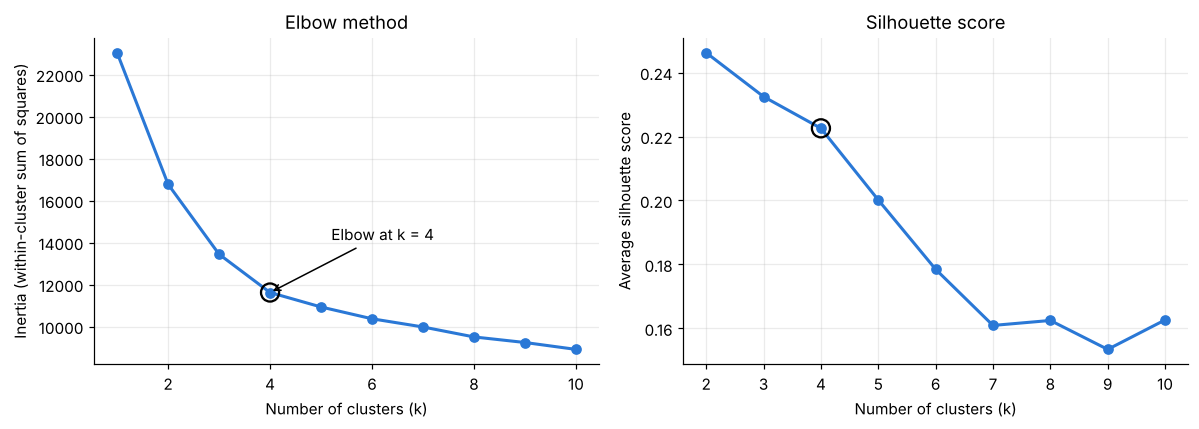

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(list(k_values), inertia, marker="o", color=COLOURS[0], linewidth=2)
axes[0].scatter([4], [inertia[3]], s=140, facecolors="none", edgecolors="black", linewidths=1.5, zorder=3)
axes[0].annotate("Elbow at k = 4", (4, inertia[3]), xytext=(5.2, inertia[3] + 2500),
                 arrowprops=dict(arrowstyle="->", color="black"))
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia (within-cluster sum of squares)")

axes[1].plot(list(k_values)[1:], silhouette[1:], marker="o", color=COLOURS[0], linewidth=2)
axes[1].scatter([4], [silhouette[3]], s=140, facecolors="none", edgecolors="black", linewidths=1.5, zorder=3)
axes[1].set(title="Silhouette score", xlabel="Number of clusters (k)", ylabel="Average silhouette score")

plt.tight_layout()
plt.savefig("../outputs/figures/fig1_elbow_silhouette.png", bbox_inches="tight")
plt.show()

**Choosing k = 4**

- The elbow curve falls steeply up to k = 4 and then flattens: each extra cluster after four removes far less inertia than the clusters before it.
- The silhouette score is highest at k = 2 and declines slowly. Two clusters would only split customers into "new" and "long-standing", which is too broad to support targeted retention strategies. At k = 4 the score is still positive and reasonable, and the clusters separate clearly in the plots below.
- Four segments are also a practical number for the business to act on, and each one has a clear, explainable profile (section 7).

Low to moderate silhouette values are normal for customer data, where people do not fall into perfectly separate groups.

## 5. Train the final K-Means model

In [12]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
raw_labels = kmeans.fit_predict(X)

print("Inertia:         ", round(kmeans.inertia_, 1))
print("Silhouette score:", round(silhouette_score(X, raw_labels), 3))

Inertia:          11619.6


Silhouette score: 0.225


In [13]:
# Stability check: retrain with different random starting points and compare the groupings.
# An Adjusted Rand Index (ARI) of 1.0 means the customers were grouped in exactly the same way.
ari = []
for seed in [0, 1, 7, 21, 99]:
    other = KMeans(n_clusters=K, n_init=10, random_state=seed).fit_predict(X)
    ari.append(adjusted_rand_score(raw_labels, other))
print("ARI against the final model:", np.round(ari, 3))

ARI against the final model: [1.    0.999 0.999 0.999 0.999]


In [14]:
# Number the clusters in a fixed, meaningful order (by average tenure, then monthly charges),
# so that the numbering is the same every time the notebook is run.
order = (pd.DataFrame({"c": raw_labels, "t": raw["tenure"], "m": raw["MonthlyCharges"]})
         .groupby("c")[["t", "m"]].mean().sort_values(["t", "m"]).index)
relabel = {old: new for new, old in enumerate(order)}
df["Cluster"] = pd.Series(raw_labels).map(relabel).values

df["Cluster"].value_counts().sort_index()

Cluster
0    1721
1    2223
2    1176
3    1923
Name: count, dtype: int64

## 6. Visualise the clusters

Variance explained by PC1 and PC2: [0.383 0.237] | total: 0.62


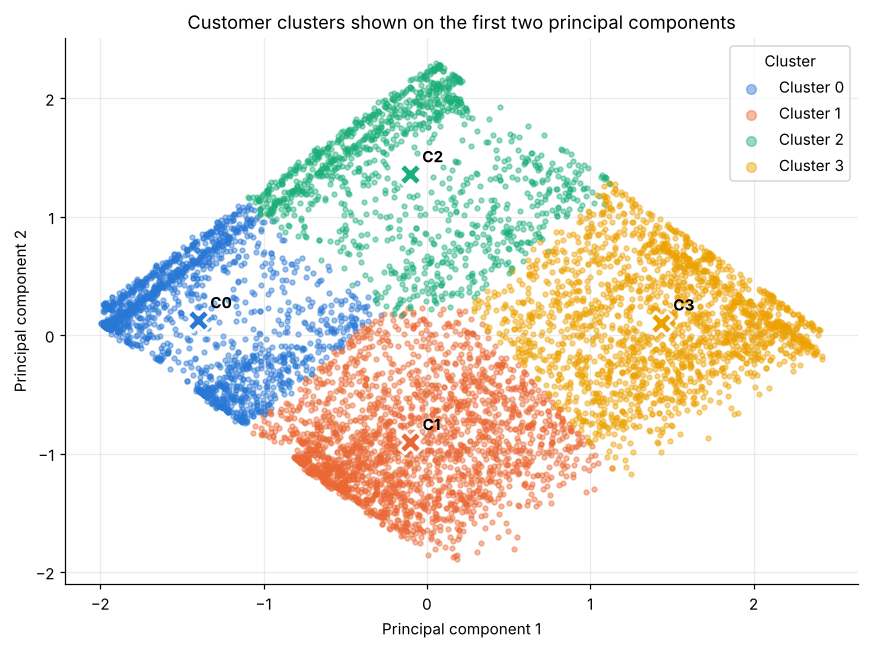

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X)
print("Variance explained by PC1 and PC2:", np.round(pca.explained_variance_ratio_, 3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))

centres = pca.transform(pd.DataFrame(kmeans.cluster_centers_, columns=features))
fig, ax = plt.subplots(figsize=(8, 6))
for c in range(K):
    m = df["Cluster"].values == c
    ax.scatter(pcs[m, 0], pcs[m, 1], s=10, alpha=0.45, color=COLOURS[c], label=f"Cluster {c}")
for old, new in relabel.items():
    ax.scatter(*centres[old], s=220, marker="X", color=COLOURS[new], edgecolors="white", linewidths=2, zorder=3)
    ax.annotate(f"C{new}", centres[old], xytext=(8, 8), textcoords="offset points", fontweight="bold")
ax.set(title="Customer clusters shown on the first two principal components",
       xlabel="Principal component 1", ylabel="Principal component 2")
ax.legend(title="Cluster", markerscale=2)
plt.tight_layout()
plt.savefig("../outputs/figures/fig2_pca_clusters.png", bbox_inches="tight")
plt.show()

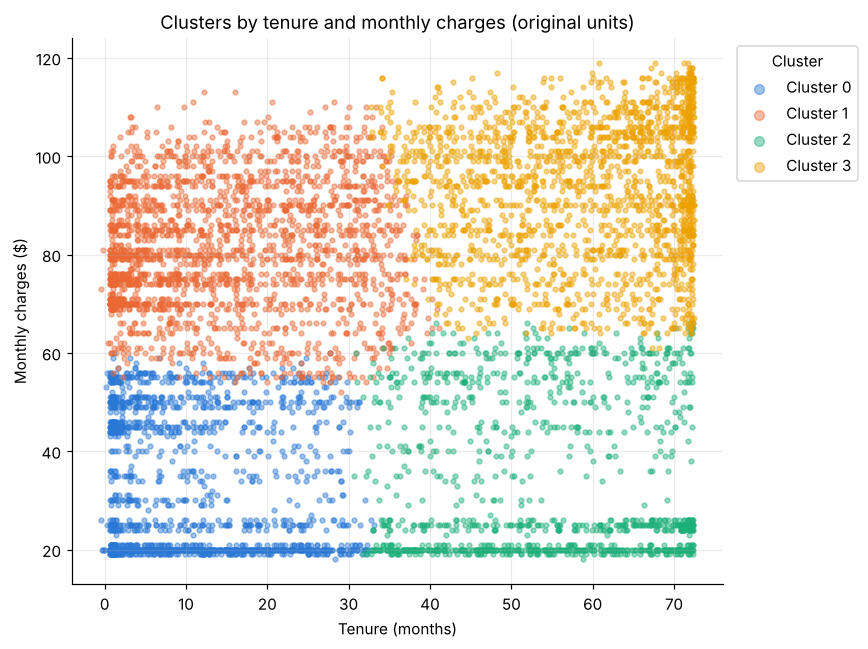

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.4, 0.4, len(raw))
for c in range(K):
    m = df["Cluster"].values == c
    ax.scatter(raw.loc[m, "tenure"] + jitter[m], raw.loc[m, "MonthlyCharges"], s=10, alpha=0.45,
               color=COLOURS[c], label=f"Cluster {c}")
ax.set(title="Clusters by tenure and monthly charges (original units)",
       xlabel="Tenure (months)", ylabel="Monthly charges ($)")
ax.legend(title="Cluster", markerscale=2, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("../outputs/figures/fig3_tenure_charges_clusters.png", bbox_inches="tight")
plt.show()

The PCA plot shows four distinct groups. The second plot, in original units, explains why: the clusters are formed mainly by **how long customers have stayed** and **how much they pay each month**, giving four combinations of short or long tenure and low or high charges.

## 7. Profile and name each segment

In [17]:
prof = raw.copy()
prof["Cluster"] = df["Cluster"].values
yes = lambda s: (s == "Yes").mean() * 100

profile = prof.groupby("Cluster").agg(
    Customers=("Cluster", "size"),
    Avg_tenure_months=("tenure", "mean"),
    Avg_monthly_charges=("MonthlyCharges", "mean"),
    Churn_rate_pct=("Churn", yes),
    Senior_pct=("SeniorCitizen", lambda s: s.mean() * 100),
    Dependents_pct=("Dependents", yes),
    Phone_pct=("PhoneService", yes),
    Multiple_lines_pct=("MultipleLines", yes),
    Fibre_pct=("InternetService", lambda s: (s == "Fiber optic").mean() * 100),
    Month_to_month_pct=("Contract", lambda s: (s == "Month-to-month").mean() * 100),
    Two_year_pct=("Contract", lambda s: (s == "Two year").mean() * 100),
)
profile.insert(1, "Share_pct", profile["Customers"] / len(prof) * 100)
profile.round(1)

,Customers,Share_pct,Avg_tenure_months,Avg_monthly_charges,Churn_rate_pct,Senior_pct,Dependents_pct,Phone_pct,Multiple_lines_pct,Fibre_pct,Month_to_month_pct,Two_year_pct
Cluster,,,,,,,,,,,,
0,1721,24.4,10.4,32.4,24.6,6.6,31.0,79.3,41.9,44.3,54.6,23.0
1,2223,31.6,14.9,81.2,49.0,23.8,17.9,99.8,42.1,42.3,55.6,25.1
2,1176,16.7,54.2,34.5,4.8,7.4,45.4,73.6,40.3,44.0,54.2,24.0
3,1923,27.3,58.8,93.3,15.5,21.5,33.4,99.5,43.7,45.5,55.3,24.0


In [18]:
names = {
    0: "New Budget Customers",
    1: "At-Risk New Premium Customers",
    2: "Loyal Budget Customers",
    3: "Loyal Premium Customers",
}
# Confirm the names match the profile (short tenure for 0-1, long for 2-3; low charges for 0 and 2, high for 1 and 3)
check = profile[["Avg_tenure_months", "Avg_monthly_charges", "Churn_rate_pct"]].round(1)
check["Segment"] = check.index.map(names)
check

,Avg_tenure_months,Avg_monthly_charges,Churn_rate_pct,Segment
Cluster,,,,
0,10.4,32.4,24.6,New Budget Customers
1,14.9,81.2,49.0,At-Risk New Premium Customers
2,54.2,34.5,4.8,Loyal Budget Customers
3,58.8,93.3,15.5,Loyal Premium Customers


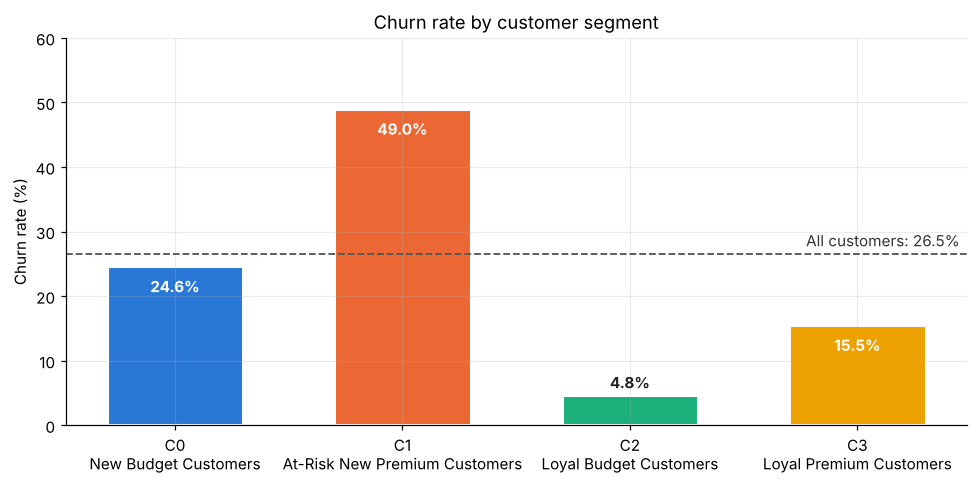

In [19]:
overall = (raw["Churn"] == "Yes").mean() * 100
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar([f"C{c}\n{names[c]}" for c in range(K)], profile["Churn_rate_pct"],
              color=COLOURS, width=0.6, edgecolor="white", linewidth=2)
ax.axhline(overall, color="#555", linestyle="--", linewidth=1.2)
ax.text(K - 0.55, overall + 1.2, f"All customers: {overall:.1f}%", ha="right", color="#333")
for b, v in zip(bars, profile["Churn_rate_pct"]):
    inside = v > 10
    ax.text(b.get_x() + b.get_width() / 2, v - 4 if inside else v + 1, f"{v:.1f}%", ha="center",
            fontweight="bold", color="white" if inside else "#222")
ax.set(title="Churn rate by customer segment", ylabel="Churn rate (%)", ylim=(0, 60))
plt.tight_layout()
plt.savefig("../outputs/figures/fig4_churn_by_cluster.png", bbox_inches="tight")
plt.show()

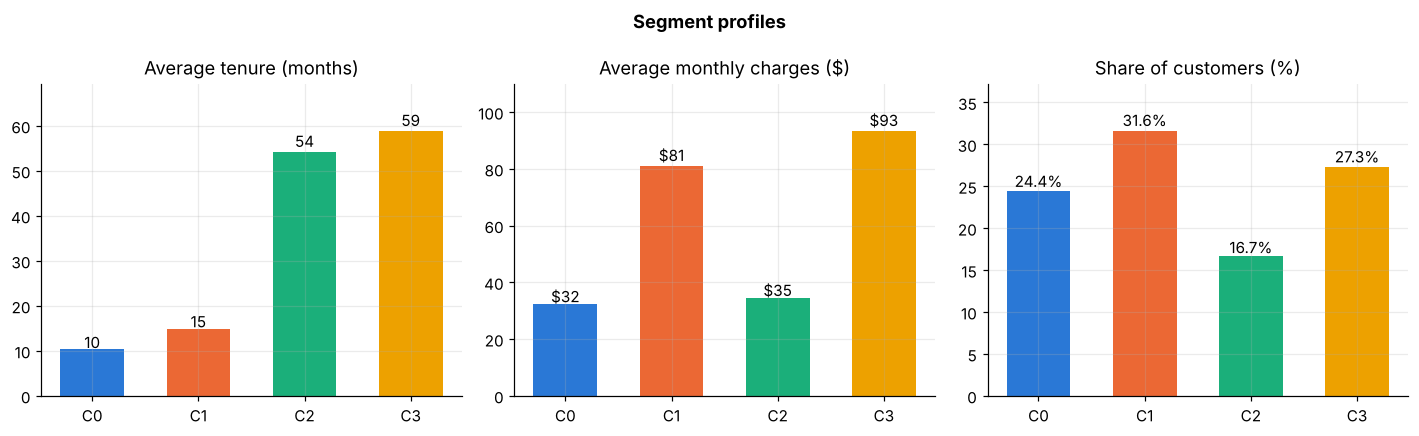

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
items = [("Avg_tenure_months", "Average tenure (months)", "{:.0f}"),
         ("Avg_monthly_charges", "Average monthly charges ($)", "${:.0f}"),
         ("Share_pct", "Share of customers (%)", "{:.1f}%")]
for ax, (col, title, fmt) in zip(axes, items):
    bars = ax.bar([f"C{c}" for c in range(K)], profile[col], color=COLOURS, width=0.6)
    for b, v in zip(bars, profile[col]):
        ax.text(b.get_x() + b.get_width() / 2, v * 1.02, fmt.format(v), ha="center")
    ax.set_title(title)
    ax.set_ylim(0, profile[col].max() * 1.18)
plt.suptitle("Segment profiles", fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/fig5_segment_profiles.png", bbox_inches="tight")
plt.show()

In [21]:
# Contract and service mix in each segment
mix = profile[["Month_to_month_pct", "Two_year_pct", "Fibre_pct", "Phone_pct", "Multiple_lines_pct",
               "Senior_pct", "Dependents_pct"]].round(1)
mix.index = [f"C{c} {names[c]}" for c in mix.index]
mix

,Month_to_month_pct,Two_year_pct,Fibre_pct,Phone_pct,Multiple_lines_pct,Senior_pct,Dependents_pct
C0 New Budget Customers,54.6,23.0,44.3,79.3,41.9,6.6,31.0
C1 At-Risk New Premium Customers,55.6,25.1,42.3,99.8,42.1,23.8,17.9
C2 Loyal Budget Customers,54.2,24.0,44.0,73.6,40.3,7.4,45.4
C3 Loyal Premium Customers,55.3,24.0,45.5,99.5,43.7,21.5,33.4


**Segment summary**

| Cluster | Segment | Profile | Churn |
|---|---|---|---|
| C0 | New Budget Customers | Recently joined (about 10 months) and on low-cost plans (about $32 a month); fewer have phone service | Moderate (about 25%) |
| C1 | At-Risk New Premium Customers | Recently joined (about 15 months) but paying high monthly charges (about $81); more seniors and fewer dependents | **Highest (about 49%)**, nearly double the average |
| C2 | Loyal Budget Customers | Long-standing (about 54 months) on low-cost plans (about $35); the most customers with dependents | Lowest (about 5%) |
| C3 | Loyal Premium Customers | Long-standing (about 59 months) and paying the most (about $93); almost all have phone service | Low (about 16%) |

**What this tells the team**

- **Tenure is the strongest dividing line.** The two new-customer segments (C0 and C1) account for most of the churn, so the first year or so of a customer's life is where retention effort matters most.
- **High charges for new customers are the riskiest combination.** C1 loses almost half of its customers. These customers pay premium prices before they have built loyalty, which makes them the first priority for retention offers.
- **Contract type and internet service are spread almost evenly across all four segments** (about 55% month-to-month and 42 to 46% fibre in each), so in this dataset they do not separate customers. The segments are driven by tenure, charges and, to a smaller degree, seniors, dependents and phone service.
- Loyal customers (C2 and C3) churn much less, but C3 still brings the highest revenue, so keeping its churn low protects a large share of income.

## 8. Save the results for the team

In [22]:
# File for the Business Analyst and for the final report: original customer attributes plus segment
out = raw.copy()
out["Cluster"] = df["Cluster"].values
out["Segment"] = out["Cluster"].map(names)
out.to_csv("../outputs/data/Clustered_Customers.csv", index=False)

# File for the Data Analyst (Predictive): the processed dataset plus the cluster label,
# which can be one-hot encoded and tested as an extra ANN input
model_ready = processed.copy()
model_ready["Cluster"] = df["Cluster"].values
model_ready.to_csv("../outputs/data/Updated_Dataset_with_Clusters.csv", index=False)

prof_out = profile.round(1).copy()
prof_out.insert(0, "Segment", prof_out.index.map(names))
prof_out.to_csv("../outputs/data/Cluster_Profiles.csv")

print("Saved to ../outputs: Clustered_Customers.csv, Updated_Dataset_with_Clusters.csv, Cluster_Profiles.csv and five figures")

Saved to ../outputs: Clustered_Customers.csv, Updated_Dataset_with_Clusters.csv, Cluster_Profiles.csv and five figures


## Notes for the team

- **Data preparation (Part 1):** the clustering uses the standardised data from Part 1 without changing it. The 302 duplicate rows were kept in both stages, so the datasets stay aligned.
- **For Bao (Data Analyst, Predictive):** `Updated_Dataset_with_Clusters.csv` adds the `Cluster` column. It can be one-hot encoded and tested as an extra input. Note that `gender` and `Dependents` are text (`Male/Female`, `Yes/No`) in the Part 1 output, so they will need converting to 0/1 before they go into the ANN. Because churn differs strongly by segment (5% to 49%), stratifying or checking results by segment may also help.
- **For Fahad (Business Analyst):** `Clustered_Customers.csv` and `Cluster_Profiles.csv` hold every customer's segment and the segment profiles for retention strategy design. C1 (At-Risk New Premium Customers) is the priority group.

**Limitations:** the dataset is a single snapshot with ten attributes and no usage, billing history or payment method data. K-Means works best with roughly round, similar-sized clusters, so the segments are best read as broad customer groups rather than exact boundaries.